<h1 style="text-align: center;">Sklearn</h1>

<p style="text-align: center;">2026-10-21</p>

课程代码均在如下 GitHub 仓库开源：<https://github.com/GHe0000/xmu_machine_learning>

项目自动生成网页地址：<https://ghe0000.github.io/xmu_machine_learning>

## 目录

- [作业要求](#作业要求)
  - [背景补充](#背景补充)
    - [Normal Equation 与核回归](#normal-equation-与核回归)
  - [任务一](#任务一)
    - [数据集准备和划分](#数据集准备和划分)
    - [特征标准化](#特征标准化)
    - [模型训练和计算](#模型训练和计算)
    - [超参优化](#超参优化)
      - [超参扫描](#超参扫描)
      - [固定 gammma 后, lambda 对 Loss 的影响](#固定-gammma-后-lambda-对-loss-的影响)
      - [固定 lambda 后, gamma 对 Loss 的影响](#固定-lambda-后-gamma-对-loss-的影响)
    - [模型评估](#模型评估)
  - [任务二](#任务二)
    - [数据集准备和划分](#数据集准备和划分)
    - [Pipline 设置和模型训练](#pipline-设置和模型训练)
    - [模型评估](#模型评估)
      - [分类边界](#分类边界)
      - [混淆矩阵](#混淆矩阵)
      - [Acc、Precision、Recall、F1](#accprecisionrecallf1)
    - [Pipeline 与防止数据泄漏](#pipeline-与防止数据泄漏)
  - [结论](#结论)
  - [参考资料及 AI 使用说明](#参考资料及-ai-使用说明)
  - [致谢](#致谢)
  - [附一：问题与思考](#附一问题与思考)
    - [高斯核 SVM 和热扩散问题的相关讨论和思考](#高斯核-svm-和热扩散问题的相关讨论和思考)
    - [高斯核 SVM 和 Hilbert 空间的相关讨论和思考](#高斯核-svm-和-hilbert-空间的相关讨论和思考)
    - [总结](#总结)
  - [附二：学习心得](#附二学习心得)

## 作业要求

1）用核方法 + normal equation 完成函数拟合任务，数据集用 $y=\sin(15x)+\xi$，其中 $x\in[0,1]$，$\xi$ 为随机扰动. 讨论 $\gamma$ 影响. 

2）用 `sklearn` 的 `Pipeline` 工作流实现 SVM 对 moon 数据集的分类. 画出分类边界和分类带. 并在理解的基础上说明其数据规范化如何防止数据泄露和超参数调优的过程. 

## 背景补充

### Normal Equation 与核回归

对于线性回归模型, 假设特征矩阵为 $\Phi$, 模型参数为 $\boldsymbol{w}$, 使用带正则化项的最小二乘损失函数

$$
J(\boldsymbol{w})=\|\Phi\boldsymbol{w}-\boldsymbol{y}\|^2
+\lambda\|\boldsymbol{w}\|^2
$$

对 $\boldsymbol{w}$ 求导并令其等于零

$$
\frac{\partial J}{\partial\boldsymbol{w}}=2\Phi^{\mathsf T}(\Phi\boldsymbol{w}-\boldsymbol{y})+2\lambda\boldsymbol{w}=0
$$

整理得到 Normal Equation

$$
(\Phi^{\mathsf T}\Phi+\lambda I)\boldsymbol{w}
=\Phi^{\mathsf T}\boldsymbol{y}
$$

如果特征维数很高, 直接求解 $\boldsymbol{w}$ 可能需要大量计算.

由于最优解可以写成

$$
\boldsymbol{w}=\Phi^{\mathsf T}\boldsymbol{\alpha}
$$

定义核矩阵

$$
K=\Phi\Phi^{\mathsf T}
$$

其中每个矩阵元素为

$$
K_{ij}=k(\boldsymbol{x}_i,\boldsymbol{x}_j)
$$

将上述形式代入 Normal Equation, 可以得到一组满足原方程的系数

$$
(K+\lambda I)\boldsymbol{\alpha}=\boldsymbol{y}
$$

因此

$$
\boldsymbol{\alpha}=(K+\lambda I)^{-1}\boldsymbol{y}
$$

在实际计算中, 我们不直接计算逆矩阵, 而使用 `np.linalg.solve` 求解线性方程组.

得到 $\boldsymbol{\alpha}$ 后, 对新的输入 $x$, 预测函数为

$$
\hat y(x)=\sum_{i=1}^{m}\alpha_i k_\gamma(x,x_i)
$$

其中 $m$ 为训练样本数量.

这种方法称为核岭回归（Kernel Ridge Regression）. 相比普通的最小二乘回归, 我们不需要显式构造高维特征, 而只需要计算训练样本之间的核矩阵.

## 任务一

### 数据集准备和划分

导入需要的库，并对 Jupyter Notebook 进行一定设置.

In [1]:
import numpy as np # 数值计算库
import numba as nb # 引入 jit 来加速函数（如果需要）
import sympy as sym # 符号计算库
import matplotlib as mpl
import matplotlib.pyplot as plt # 图像绘制
from matplotlib.backends.backend_agg import FigureCanvasAgg # 设置图像后端用
import ipywidgets as ipw # 交互控件
from IPython.display import display, Math, Latex # 打印数学公式
import time
import tracemalloc
import matplotlib.text as mtext

import pandas as pd

from io import BytesIO
import matplotlib.animation as animation # 创建动画
from IPython.display import HTML # 动画嵌入
import scipy

from sklearn.datasets import make_moons, make_blobs, make_circles, make_classification

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 使用 mathjax 来在 jupyter notebook 显示数学公式
sym.init_printing(use_latex='mathjax')

# 设置 matplotlib 绘制的图像嵌入到 jupyter notebook 的方式
%matplotlib widget

# 一个工具函数，可以让静态图片不经过 widget 直接嵌入 Jupyter notebook
# 这样图片可以直接存到 nb 文件里，而不是需要运行才能显示（类似 inline）
def display_inline(fig):
    try:
        try:
            fig.canvas.draw()
            fig.canvas.flush_events()
        except Exception:
            pass

        fig.set_canvas(FigureCanvasAgg(fig))
        try:


            if hasattr(mtext, "_get_text_metrics_with_cache_impl"):
                mtext._get_text_metrics_with_cache_impl.cache_clear()
        except Exception:
            pass
        try:
            fig.draw_without_rendering()
        except Exception:
            pass
        fig.tight_layout()
        fig.canvas.draw()
        display(fig)

    finally:
        plt.close(fig)  # 释放 fig，减小资源消耗

# 一个工具函数，用于在 Jupyter 中快速实现公式和字符串混合输出
def display_math(*args):
    parts = []
    for a in args:
        if isinstance(a, str):
            parts.append(a)
        else:
            parts.append(sym.latex(a))
    display(Math("".join(parts)))

# 设置 matplotlib 使用的字体，避免出现中文问题
plt.rcParams.update({
    # 字体
    "font.family": ["SimSun", "Times New Roman"],
    "font.size": 14,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    # 字号
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 14,
})

# 设置种子，保证可重复性
rng = np.random.default_rng(3407)

根据题目要求，生成 $y=\sin(15x) + \xi$ 的数据集，$\xi$ 为 $-0.2$ 到 $0.2$ 的均匀分布的随机噪声，我们生成 $300$ 个点，并按 6:2:2 划分 Train Val Test

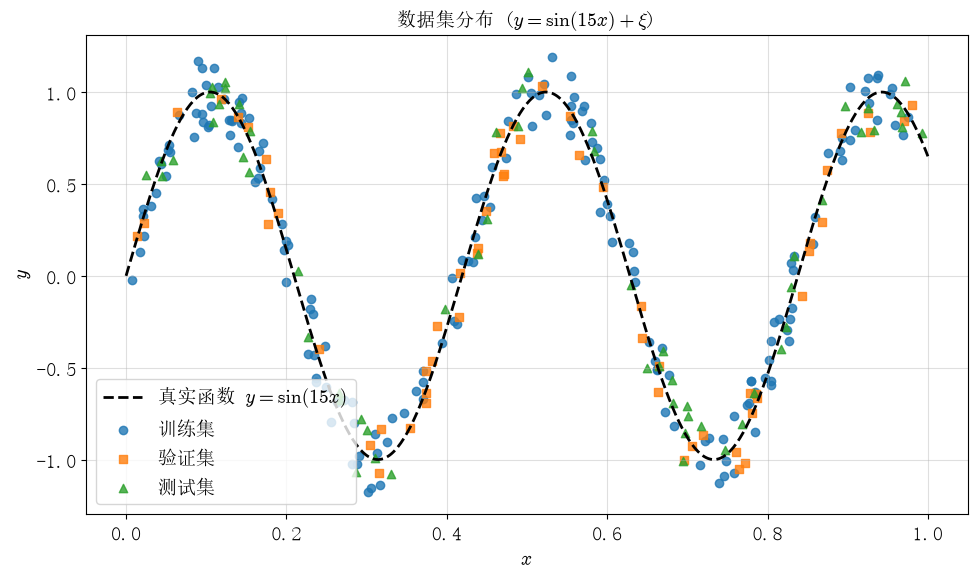

In [2]:
m_total = 300

rng_reg = np.random.default_rng(42)
x_all = rng_reg.uniform(0.0, 1.0, size=(m_total, 1))
xi = rng_reg.uniform(-0.2, 0.2, size=(m_total, 1))
y_all = np.sin(15.0 * x_all) + xi

idx_perm = rng_reg.permutation(m_total)
n_train = int(0.6 * m_total)
n_val = int(0.2 * m_total)

idx_train = idx_perm[:n_train]
idx_val = idx_perm[n_train:n_train + n_val]
idx_test = idx_perm[n_train + n_val:]

x_train = x_all[idx_train].copy(); y_train = y_all[idx_train].flatten()
x_val = x_all[idx_val].copy(); y_val = y_all[idx_val].flatten()
x_test = x_all[idx_test].copy(); y_test = y_all[idx_test].flatten()

x_dense = np.linspace(0.0, 1.0, 500).reshape(-1, 1)
y_true_dense = np.sin(15.0 * x_dense).ravel()
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_dense, y_true_dense, "k--", linewidth=2, label=r"真实函数 $y=\sin(15x)$")
ax.scatter(x_train, y_train, c="C0", marker="o", alpha=0.8, label="训练集")
ax.scatter(x_val, y_val, c="C1", marker="s", alpha=0.8, label="验证集")
ax.scatter(x_test, y_test, c="C2", marker="^", alpha=0.8, label="测试集")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_title(r"数据集分布 ($y=\sin(15x)+\xi$)")
ax.grid(True, alpha=0.4)
ax.legend(loc="lower left")
display_inline(fig)


### 特征标准化

由于不同特征的取值范围可能存在较大差异, 直接使用原始数据计算高斯核时, 数值尺度较大的特征可能主导样本之间的距离, 进而影响模型的拟合效果.

因此, 在训练模型之前, 我们先对输入特征进行标准化（Standardization）, 使每个特征的均值为 $0$, 标准差为 $1$.

对于第 $j$ 个特征, 标准化公式为

$$
x'_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}
$$

In [3]:
def standardize_features(X_train, X_val, X_test):
    mean = np.mean(X_train, axis=0)
    std = np.std(X_train, axis=0)
    std = np.where(std > 1e-12, std, 1.0)
    X_train_std = (X_train - mean) / std
    X_val_std = (X_val - mean) / std
    X_test_std = (X_test - mean) / std
    return X_train_std, X_val_std, X_test_std, mean, std

x_train_raw = x_train.copy()
x_val_raw = x_val.copy()
x_test_raw = x_test.copy()

x_train, x_val, x_test, feature_mean, feature_std = standardize_features(x_train, x_val, x_test)

### 模型训练和计算

我们首先实现高斯核函数, 用于计算两个数据集之间的核矩阵.

对于训练集 $X_{\mathrm{train}}$, 构造核矩阵

$$
K_{ij}=\exp\left(-\gamma\|x_i-x_j\|^2\right)
$$

根据前面推导的 Normal Equation, 求解

$$
(K+\lambda I)\boldsymbol{\alpha}=\boldsymbol{y}_{\mathrm{train}}
$$

这里引入 $\lambda>0$ 是为了避免核矩阵接近奇异时产生数值不稳定. 当 $\lambda=0$ 时, 上式退化为没有正则化的核插值方程 $K\boldsymbol{\alpha}=\boldsymbol y$.

本次初始模型取

$$
\gamma=100,\qquad \lambda=10^{-2}
$$

使用 `np.linalg.solve` 求解模型参数, 然后计算 Train 和 Val 的 MSE, 并绘制拟合曲线.

In [4]:
@nb.njit
def squared_distances(X1, X2):
    m, d = X1.shape
    n = X2.shape[0]
    D2 = np.empty((m, n), dtype=np.float64)
    for i in range(m):
        for j in range(n):
            dist2 = 0.0
            for k in range(d):
                dist2 += (X1[i, k] - X2[j, k])**2
            D2[i, j] = dist2
    return D2

@nb.njit
def rbf_from_distance(D2, gamma):
    return np.exp(-gamma * D2)

@nb.njit
def mse_loss(y, y_pred):
    return np.mean((y - y_pred)**2)

def train_kernel_ridge(X_train, y_train, gamma, lam):
    D2 = squared_distances(X_train, X_train)
    K = rbf_from_distance(D2, gamma)
    alpha = np.linalg.solve(K + lam * np.eye(len(y_train)), y_train)
    return alpha

def predict_kernel_ridge(X, X_train, alpha, gamma):
    D2 = squared_distances(X, X_train)
    K = rbf_from_distance(D2, gamma)
    return K @ alpha

In [5]:
gamma_init = 100.0
lambda_init = 0.01

alpha_init = train_kernel_ridge(x_train, y_train, gamma_init, lambda_init)

y_pred_train_init = predict_kernel_ridge(x_train, x_train, alpha_init, gamma_init)
y_pred_val_init = predict_kernel_ridge(x_val, x_train, alpha_init, gamma_init)

print(f"Train MSE = {mse_loss(y_train, y_pred_train_init):.6f}")
print(f"Val MSE = {mse_loss(y_val, y_pred_val_init):.6f}")

Train MSE = 0.009858
Val MSE = 0.016806


进一步画出拟合曲线，有：

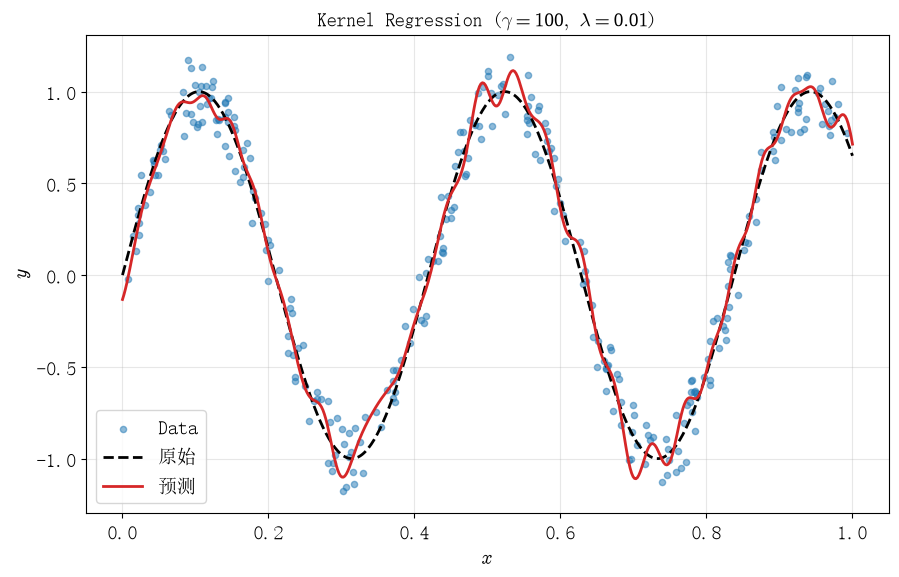

In [6]:
x_dense_std = (x_dense - feature_mean) / feature_std
y_pred_dense_init = predict_kernel_ridge(x_dense_std, x_train, alpha_init, gamma_init)

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(x_all, y_all, c="C0", s=20, alpha=0.5, label="Data")
ax.plot(x_dense, y_true_dense, "k--", linewidth=2, label="原始")
ax.plot(x_dense, y_pred_dense_init, c="C3", linewidth=2, label="预测")

ax.set(
    xlabel="$x$", ylabel="$y$",
    title=fr"Kernel Regression ($\gamma={gamma_init:g},\ \lambda={lambda_init:g}$)"
)
ax.grid(True, alpha=0.3)
ax.legend()
display_inline(fig)

从拟合曲线可以看见, 初始模型已经能够基本描述原函数的振荡结构, 但预测曲线在局部区域仍然存在一定偏差.

此时我们取 $\gamma=100,\lambda=0.01$, 得到 Train MSE 为 $0.009858$, Val MSE 为 $0.016806$. 验证集误差明显大于训练集误差, 说明模型可能对训练数据中的随机噪声产生了一定程度的过拟合.

由于模型的拟合效果同时受到 $\gamma$ 和 $\lambda$ 的影响, 下面进一步通过超参数扫描优化模型.

### 超参优化

#### 超参扫描

在核岭回归中, $\gamma$ 和 $\lambda$ 分别控制核函数的宽度和正则化强度, 两者都会影响模型的拟合效果.

因此, 本次同时扫描两个超参数, 分别取

$$
10^{-2}\leq\gamma\leq10^4
$$

$$
10^{-5}\leq\lambda\leq1
$$

在对数上取点扫描，并绘制二维的 Loss-超参图.

In [7]:
@nb.njit(parallel=True)
def scan_kernel_parameters(
    X_train, y_train, X_val, y_val,
    gamma_values, lambda_values
):
    n_gamma = len(gamma_values)
    n_lambda = len(lambda_values)
    n_train = len(y_train)
    
    train_mse = np.empty((n_gamma, n_lambda))
    val_mse = np.empty((n_gamma, n_lambda))

    D2_train = squared_distances(X_train, X_train)
    D2_val = squared_distances(X_val, X_train)

    for i in nb.prange(n_gamma):
        gamma = gamma_values[i]
        K_train = rbf_from_distance(D2_train, gamma)
        K_val = rbf_from_distance(D2_val, gamma)

        for j in range(n_lambda):
            A = K_train.copy()
            for k in range(n_train):
                A[k, k] += lambda_values[j]

            alpha = np.linalg.solve(A, y_train)

            y_pred_train = K_train @ alpha
            y_pred_val = K_val @ alpha

            train_mse[i, j] = mse_loss(y_train, y_pred_train)
            val_mse[i, j] = mse_loss(y_val, y_pred_val)

    return train_mse, val_mse

In [8]:
gamma_values = np.logspace(-2, 4, 25)
lambda_values = np.logspace(-5, 0, 16)

_ = scan_kernel_parameters(
    x_train[:3], y_train[:3], x_val[:3], y_val[:3],
    gamma_values[:1], lambda_values[:1]
)

t_start = time.time()
print("开始扫描 Gamma 和 Lambda......")

train_mse_grid, val_mse_grid = scan_kernel_parameters(
    x_train, y_train, x_val, y_val,
    gamma_values, lambda_values
)

print(f"扫描完成, 耗时 {time.time() - t_start:.2f} s")

开始扫描 Gamma 和 Lambda......
扫描完成, 耗时 0.22 s


In [9]:
best_index = np.unravel_index(np.argmin(val_mse_grid), val_mse_grid.shape)
best_gamma = gamma_values[best_index[0]]
best_lambda = lambda_values[best_index[1]]
print(f"Best Model Train Loss:{train_mse_grid[*best_index]:6f}")
print(f"Best Model Val Loss:{val_mse_grid[*best_index]:6f}")

Best Model Train Loss:0.012537
Best Model Val Loss:0.011739


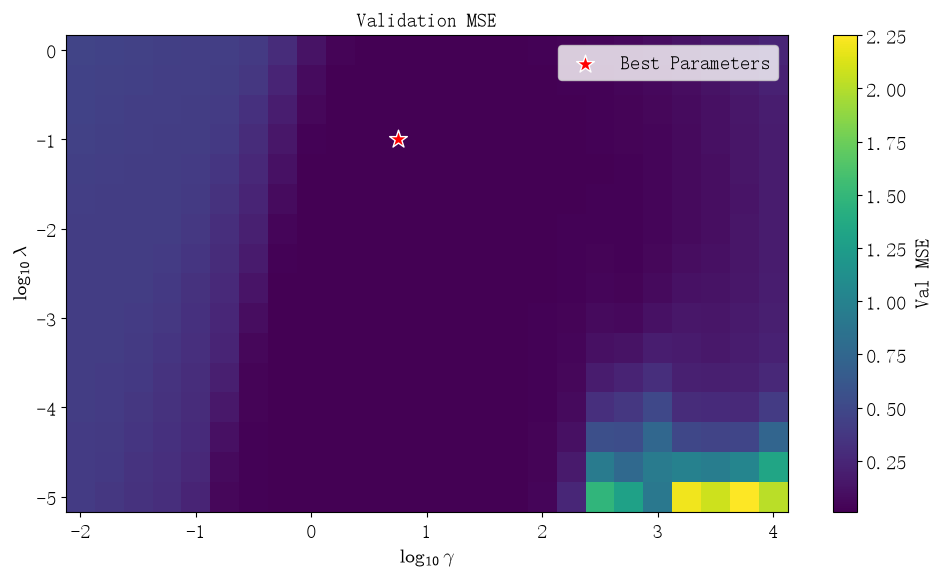

In [10]:
log_gamma = np.log10(gamma_values)
log_lambda = np.log10(lambda_values)

fig, ax = plt.subplots(figsize=(10, 6))

im = ax.pcolormesh(
    log_gamma, log_lambda, val_mse_grid.T,
    shading="nearest", cmap="viridis"
)

ax.scatter(
    log_gamma[best_index[0]], log_lambda[best_index[1]],
    c="red", marker="*", s=180, edgecolors="white",
    zorder=3, label="Best Parameters"
)

ax.set(
    xlabel=r"$\log_{10}\gamma$",
    ylabel=r"$\log_{10}\lambda$",
    title="Validation MSE"
)

fig.colorbar(im, ax=ax, label="Val MSE")
ax.legend()
display_inline(fig)

绘制 Val MSE 关于 $\log_{10}\gamma$ 和 $\log_{10}\lambda$ 的二维热力图, 从图中可以看见, 两个参数对模型性能的影响存在一定的耦合.

当 $\gamma$ 较小时, 核函数的变化过于缓慢, 模型难以描述原函数的振荡结构, 验证误差较大. 随着 $\gamma$ 增大, 模型的拟合能力逐渐提高, 验证误差明显下降. 但当 $\gamma$ 过大时, 验证误差又会增加.

对于 $\lambda$, 适当的正则化可以提高模型的泛化能力, 但最优的 $\lambda$ 会随 $\gamma$ 的变化而改变.

在本次扫描中, Val MSE 最小的参数组合为

$$
\gamma\approx5.6234,\qquad\lambda=0.1
$$

对应的误差为

$$
\mathrm{Train\ MSE}\approx0.012537
$$

$$
\mathrm{Val\ MSE}\approx0.011739
$$

这表明同时优化两个参数能够获得相比之前更好的拟合效果. 下面分别固定其中一个参数, 进一步分析另一个参数对模型的影响.

#### 固定 gammma 后, lambda 对 Loss 的影响

首先固定不同的 $\gamma$, 分别绘制 Val MSE 随 $\log_{10}\lambda$ 变化的曲线. 并选取具有代表性的 $\lambda$ 的曲线.

In [11]:
gamma_indices = np.linspace(0, len(gamma_values) - 1, 4, dtype=int)
lambda_indices = np.linspace(0, len(lambda_values) - 1, 4, dtype=int)

gamma_indices[np.argmin(np.abs(gamma_indices - best_index[0]))] = best_index[0]
lambda_indices[np.argmin(np.abs(lambda_indices - best_index[1]))] = best_index[1]

log_gamma = np.log10(gamma_values)
log_lambda = np.log10(lambda_values)

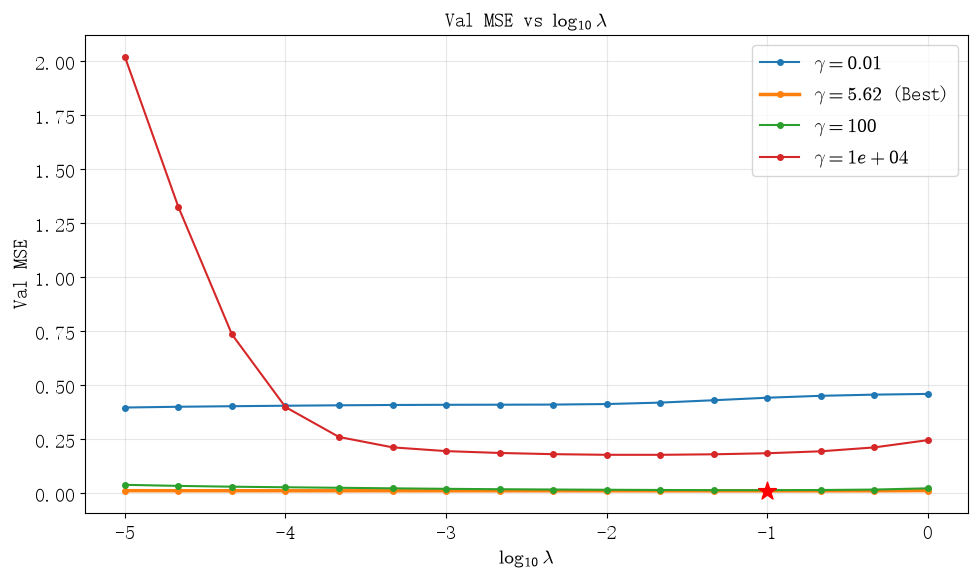

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

for i in gamma_indices:
    is_best = i == best_index[0]
    ax.plot(
        log_lambda, val_mse_grid[i, :],
        marker="o", markersize=4,
        linewidth=2.5 if is_best else 1.5,
        label=fr"$\gamma={gamma_values[i]:.3g}$" + (" (Best)" if is_best else "")
    )

ax.scatter(
    log_lambda[best_index[1]], val_mse_grid[best_index],
    c="red", marker="*", s=180, zorder=5
)

ax.set(
    xlabel=r"$\log_{10}\lambda$",
    ylabel="Val MSE",
    title=r"Val MSE vs $\log_{10}\lambda$"
)
ax.grid(True, alpha=0.3)
ax.legend()
display_inline(fig)

可以看见，随着 $\lambda$ 增大，过拟合得到限制，但 $\lambda$ 过大后，Loss 反而上升，$\lambda$ 对模型约束过大，导致欠拟合.

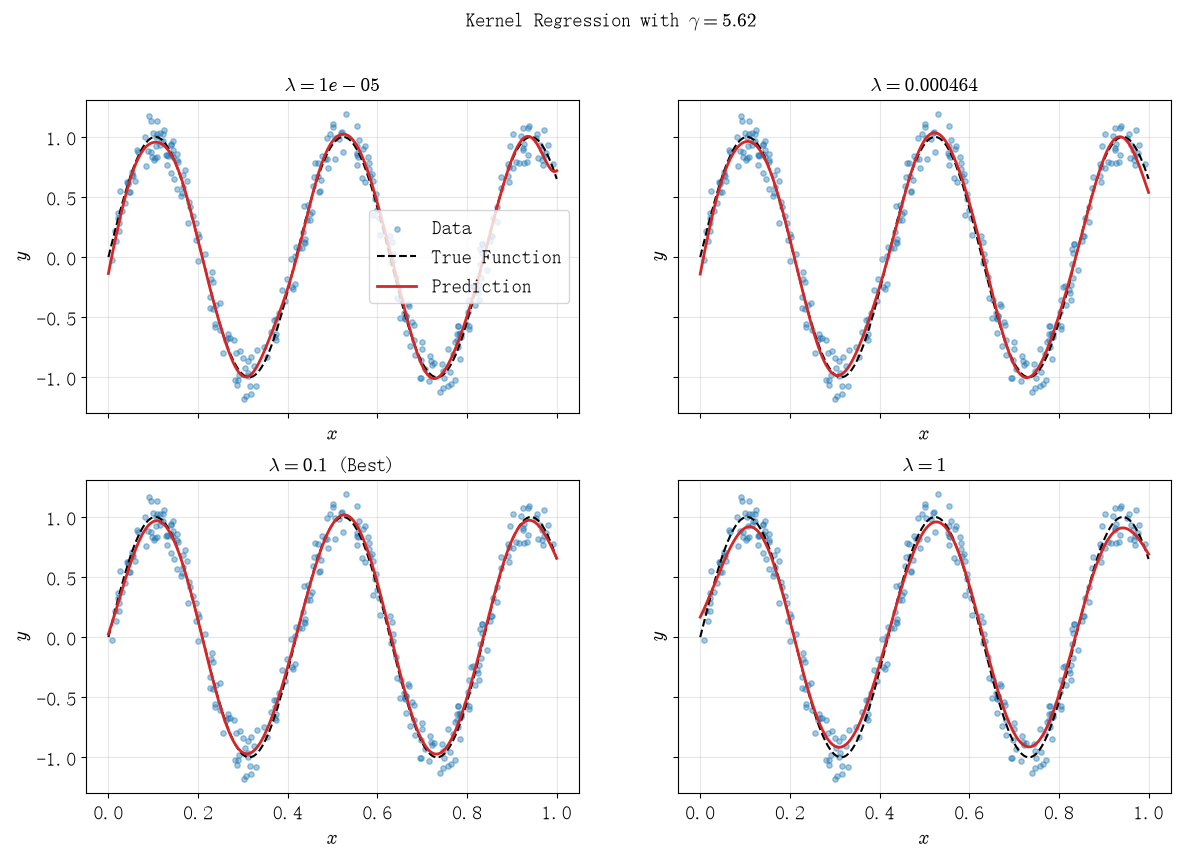

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)

for ax, j in zip(axes.flat, lambda_indices):
    lam = lambda_values[j]
    alpha = train_kernel_ridge(x_train, y_train, best_gamma, lam)
    y_pred = predict_kernel_ridge(x_dense_std, x_train, alpha, best_gamma)

    ax.scatter(x_all, y_all, c="C0", s=15, alpha=0.4, label="Data")
    ax.plot(x_dense, y_true_dense, "k--", linewidth=1.5, label="True Function")
    ax.plot(x_dense, y_pred, c="C3", linewidth=2, label="Prediction")

    is_best = j == best_index[1]
    ax.set(
        xlabel="$x$", ylabel="$y$",
        title=fr"$\lambda={lam:.3g}$" + (" (Best)" if is_best else "")
    )
    ax.grid(True, alpha=0.3)

axes[0, 0].legend()
fig.suptitle(fr"Kernel Regression with $\gamma={best_gamma:.3g}$", fontsize=14)
display_inline(fig)

理论上，当 $\lambda$ 较小时, 正则化作用较弱, 模型可以更加接近训练数据, 但可能拟合随机噪声. 随着 $\lambda$ 增大, 模型参数受到更强的约束, 拟合曲线会逐渐趋于平滑. 当 $\lambda$ 过大时, 模型的表达能力受到限制, 可能发生欠拟合.

不过本次实验中这种变化并不明显，$\lambda$ 对我们拟合的影响不是很明显.

#### 固定 lambda 后, gamma 对 Loss 的影响

接下来固定不同的 $\lambda$, 绘制 Val MSE 随 $\log_{10}\gamma$ 变化的曲线.

类似地, 选取四组具有代表性的 $\lambda$, 并在固定最优 $\lambda$ 的情况下, 比较不同 $\gamma$ 对拟合函数形状的影响.

高斯核的宽度与 $\gamma$ 的关系为

$$
\sigma=\frac{1}{\sqrt{2\gamma}}
$$

当 $\gamma$ 较小时, 核函数的作用范围较大, 模型的局部变化能力较弱. 随着 $\gamma$ 增大, 核函数的作用范围缩小, 模型可以描述更加复杂的局部变化.

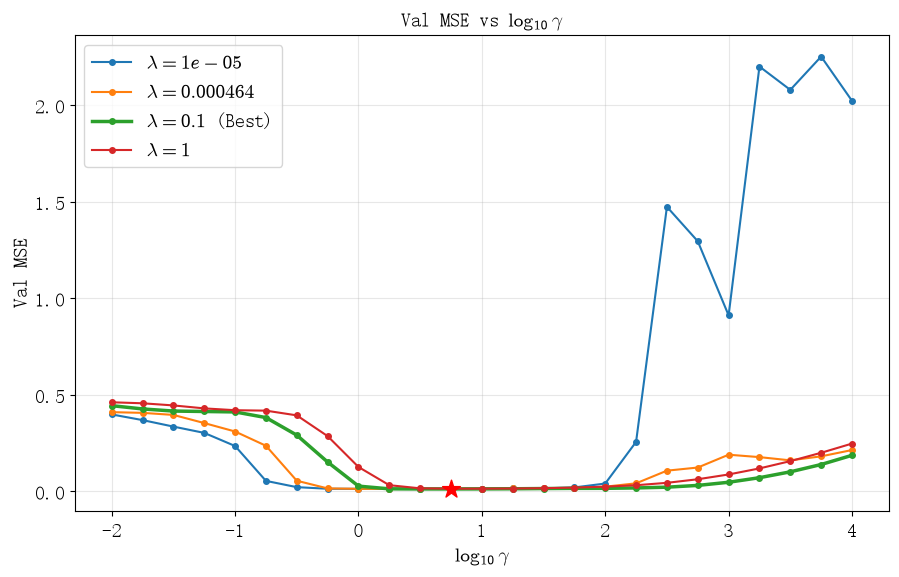

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

for j in lambda_indices:
    is_best = j == best_index[1]
    ax.plot(
        log_gamma, val_mse_grid[:, j],
        marker="o", markersize=4,
        linewidth=2.5 if is_best else 1.5,
        label=fr"$\lambda={lambda_values[j]:.3g}$" + (" (Best)" if is_best else "")
    )

ax.scatter(
    log_gamma[best_index[0]], val_mse_grid[best_index],
    c="red", marker="*", s=180, zorder=5
)

ax.set(
    xlabel=r"$\log_{10}\gamma$",
    ylabel="Val MSE",
    title=r"Val MSE vs $\log_{10}\gamma$"
)
ax.grid(True, alpha=0.3)
ax.legend()
display_inline(fig)

从 MSE-log gamma 图中，我们可以看到，随着 $\gamma$ 增大，MSE 先下降后上升，呈现标准的“欠学习-过学习”的过程.

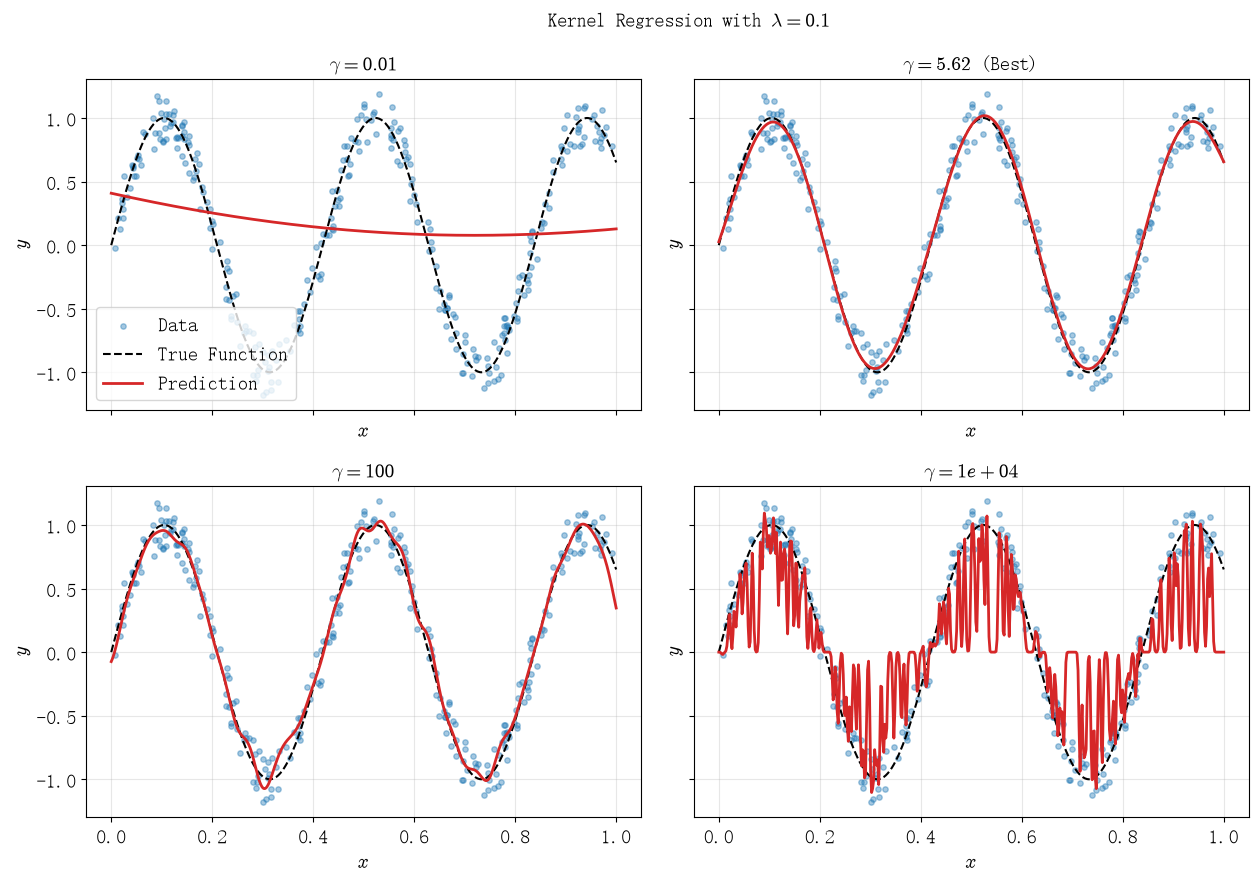

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)

for ax, i in zip(axes.flat, gamma_indices):
    gamma = gamma_values[i]
    alpha = train_kernel_ridge(x_train, y_train, gamma, best_lambda)
    y_pred = predict_kernel_ridge(x_dense_std, x_train, alpha, gamma)

    ax.scatter(x_all, y_all, c="C0", s=15, alpha=0.4, label="Data")
    ax.plot(x_dense, y_true_dense, "k--", linewidth=1.5, label="True Function")
    ax.plot(x_dense, y_pred, c="C3", linewidth=2, label="Prediction")

    is_best = i == best_index[0]
    ax.set(
        xlabel="$x$", ylabel="$y$",
        title=fr"$\gamma={gamma:.3g}$" + (" (Best)" if is_best else "")
    )
    ax.grid(True, alpha=0.3)

axes[0, 0].legend()
fig.suptitle(fr"Kernel Regression with $\lambda={best_lambda:.3g}$", fontsize=14)
display_inline(fig)

从不同 $\gamma$ 的拟合曲线中, 可以明显观察到模型从欠拟合到过拟合的变化过程.

本次固定最优 $\lambda=0.1$, 分别取

$$
\gamma=0.01,\quad5.6234,\quad100,\quad10000
$$

1. **$\gamma=0.01$**：核函数的作用范围过大, 模型难以描述原函数的振荡结构, 出现明显的欠拟合
2. **$\gamma=5.6234$**：模型能够较好地描述原函数的振荡结构, 同时没有明显地拟合随机噪声
3. **$\gamma=100$**：模型的局部变化能力进一步增强, Train MSE 降低, 但 Val MSE 增大, 已经出现一定程度的过拟合.
4. **$\gamma=10000$**：核函数的作用范围非常小, 模型主要受到附近训练样本的影响, 难以在样本之间形成稳定的预测函数. 模型严重过拟合.

这说明 $\gamma$ 对模型的复杂度具有明显影响. 与 $\lambda$ 相比, 在本次扫描范围内, $\gamma$ 的变化能够引起更大的验证误差变化. 因此, 对高斯核回归而言, 选择合适的核宽度尤为重要.

### 模型评估

根据前面的超参数扫描结果, 选择最优参数

$$
\gamma\approx5.6234,\qquad\lambda=0.1
$$

使用 Train 求解最终模型参数, 然后分别在 Train、Val 和 Test 上评估预测结果.

对于回归问题, 我们采用 MSE 和 $R^2$ 两个指标.

MSE：

$$
\mathrm{MSE}=\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat y_i)^2
$$

$R^2$：

$$
R^2=1-\frac{\sum_{i=1}^{m}(y_i-\hat y_i)^2}
{\sum_{i=1}^{m}(y_i-\bar y)^2}
$$

In [16]:
alpha_best = train_kernel_ridge(x_train, y_train, best_gamma, best_lambda)
y_pred_test = predict_kernel_ridge(x_test, x_train, alpha_best, best_gamma)

test_mse = mse_loss(y_test, y_pred_test)
test_r2 = 1 - np.sum((y_test - y_pred_test)**2) / np.sum((y_test - np.mean(y_test))**2)

print(f"Best Gamma = {best_gamma:.6f}")
print(f"Best Lambda = {best_lambda:.6f}")
print(f"Test MSE = {test_mse:.6f}")
print(f"Test R2 = {test_r2:.6f}")

Best Gamma = 5.623413
Best Lambda = 0.100000
Test MSE = 0.013194
Test R2 = 0.975873


最终选择的最优超参数为

$$
\gamma=5.623413,\qquad\lambda=0.1
$$

在 Test 上得到 MSE 为 $0.013194$, $R^2$ 为 $0.975873$, 表明模型能够较准确地预测未参与训练的数据, 具有较好的泛化能力.

由于本次数据中包含均匀分布的随机噪声

$$
\xi\sim U(-0.2,0.2)
$$

其标准差为

$$
\sigma_\xi=\frac{0.2}{\sqrt{3}}\approx0.11547
$$

而模型在 Test 上的 RMSE 约为 $0.11487$, 与噪声标准差非常接近. 这说明模型的预测误差已接近随机噪声造成的误差水平, 模型能够较好地恢复原函数的变化规律.

## 任务二

### 数据集准备和划分

我们使用上次作业的数据集，并按 8:2 划分 Train 和 Test，Train 中包含 CV 集合.

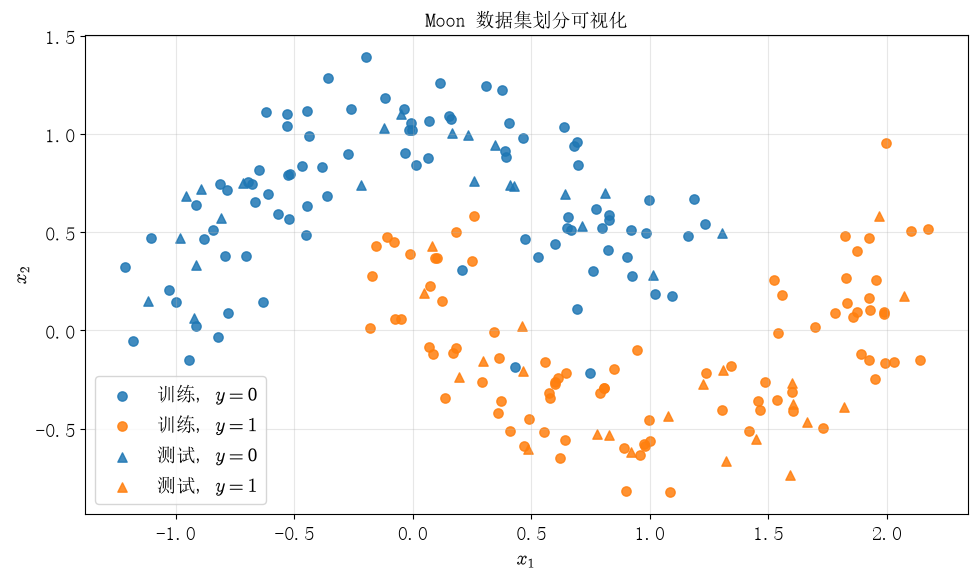

In [17]:
X_moon, y_moon = make_moons(n_samples=220, noise=0.18, random_state=44)

X_m_train, X_m_test, y_m_train, y_m_test = train_test_split(
    X_moon, y_moon, test_size=0.2, random_state=42, stratify=y_moon
)

fig, ax = plt.subplots(figsize=(10, 6))
for X_part, y_part, marker, name in [
    (X_m_train, y_m_train, "o", "训练"),
    (X_m_test, y_m_test, "^", "测试")
]:
    ax.scatter(
        X_part[y_part == 0, 0], X_part[y_part == 0, 1],
        c="C0", marker=marker, s=45, alpha=0.85, label=fr"{name}, $y=0$"
    )
    ax.scatter(
        X_part[y_part == 1, 0], X_part[y_part == 1, 1],
        c="C1", marker=marker, s=45, alpha=0.85, label=fr"{name}, $y=1$"
    )
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Moon 数据集划分可视化")
ax.grid(True, alpha=0.3)
ax.legend(loc = 'lower left')
display_inline(fig)


### Pipline 设置和模型训练

本次使用 `sklearn` 的 `Pipeline` 构建 SVM 分类模型. Pipeline 可以将数据预处理和模型训练整合，传入一个数据集，得到一个模型.

我们使用如下 Pipline

- `StandardScaler` 将输入特征标准化
- 使用 `SVC` 进行分类.

由于 Moon 数据集无法通过线性分类边界完全分开, 因此选择高斯核

$$
k_\gamma(\boldsymbol{x}_i,\boldsymbol{x}_j)
=\exp\left(-\gamma\|\boldsymbol{x}_i-\boldsymbol{x}_j\|^2\right)
$$

其中 $\gamma$ 控制高斯核的宽度. 同时, SVM 使用参数 $C$ 控制对间隔违反的惩罚程度.

- $C$ 越大, 模型越倾向于减少训练集上的分类错误, 但可能导致过拟合.
- $\gamma$ 越大, 模型能够描述更加局部的变化, 但也可能过度拟合噪声.

因此, 我们使用 `GridSearchCV` 同时优化 $C$ 和 $\gamma$, 分别在对数尺度上选取

$$
10^{-5}\leq C\leq10^5
$$

$$
10^{-5}\leq\gamma\leq10^5
$$

每个参数取 $10$ 个值, 共 $100$ 组参数组合.

使用 5 次交叉验证, 每次使用 Train 的 $4/5$ 训练模型, 剩余 $1/5$ 进行验证, 最后计算平均验证准确率

选择平均 CV Accuracy 最高的参数组合.

In [18]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf"))
])

C_values = np.logspace(-5, 5, 10)
gamma_values_svm = np.logspace(-5, 5, 10)

param_grid = {
    "svc__C": C_values,
    "svc__gamma": gamma_values_svm
}

grid_search = GridSearchCV(
    svm_pipeline, param_grid,
    scoring="accuracy", cv=5, n_jobs=-1,
    return_train_score=True
)

t_start = time.time()
print("开始扫描 C 和 Gamma......")

grid_search.fit(X_m_train, y_m_train)

best_model = grid_search.best_estimator_
best_C = grid_search.best_params_["svc__C"]
best_gamma_svm = grid_search.best_params_["svc__gamma"]

print(f"扫描完成, 耗时 {time.time() - t_start:.2f} s")
print(f"Best C = {best_C:.6f}")
print(f"Best Gamma = {best_gamma_svm:.6f}")
print(f"Best CV Accuracy = {grid_search.best_score_:.6f}")

开始扫描 C 和 Gamma......
扫描完成, 耗时 51.52 s
Best C = 0.278256
Best Gamma = 3.593814
Best CV Accuracy = 0.977143


为了观察两个超参数对 SVM 分类性能的共同影响, 我们绘制平均 CV Accuracy 关于 $\log_{10}C$ 和 $\log_{10}\gamma$ 的二维热力图.

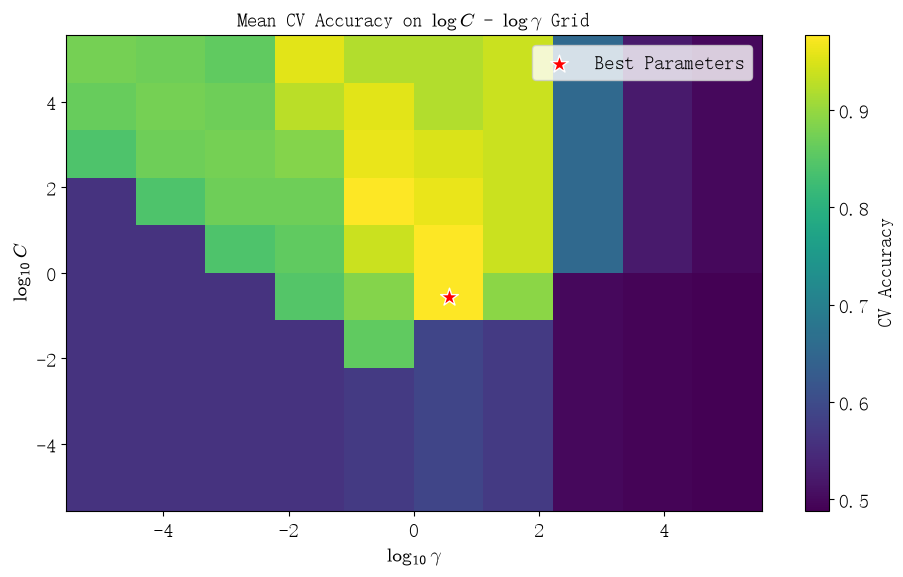

In [19]:
cv_score_grid = grid_search.cv_results_["mean_test_score"].reshape(
    len(C_values), len(gamma_values_svm)
)

log_C = np.log10(C_values)
log_gamma_svm = np.log10(gamma_values_svm)

fig, ax = plt.subplots(figsize=(10, 6))

im = ax.pcolormesh(
    log_gamma_svm, log_C, cv_score_grid,
    shading="nearest", cmap="viridis"
)

ax.scatter(
    np.log10(best_gamma_svm), np.log10(best_C),
    c="red", marker="*", s=180, edgecolors="white",
    zorder=3, label="Best Parameters"
)

ax.set(
    xlabel=r"$\log_{10}\gamma$",
    ylabel=r"$\log_{10}C$",
    title=r"Mean CV Accuracy on $\log C$ - $\log \gamma$ Grid"
)

fig.colorbar(im, ax=ax, label="CV Accuracy")
ax.legend()
display_inline(fig)

从超参数扫描结果可以看见, $C$ 和 $\gamma$ 对 SVM 的分类性能具有共同影响.

1. 当 $C$ 较小时：模型对间隔违反的惩罚较弱, 分类边界受到较强的约束, 可能无法充分拟合数据的非线性结构, 导致欠拟合.
2. 当 $\gamma$ 较小时：高斯核的作用范围较大, 分类边界更加平滑, 难以描述 Moon 数据集复杂的分类边界, 导致分类准确率下降.
3. 当 $C$ 和 $\gamma$ 较大时：模型能够描述更加局部的变化, 但也更容易受到训练数据中随机噪声的影响, 可能出现过拟合.
4. 在适当的参数范围内：模型能够较好地拟合 Moon 数据集，取得较高的 CV Accuracy. 同时热力图中存在连续的高准确率区域, 也说明模型对该区域内的参数变化具有一定的稳定性.

本次扫描得到的最优参数为

$$
C = 0.278256,\quad \gamma = 3.593814
$$

此时

$$
CV Acc = 0.977143
$$

### 模型评估

#### 分类边界

对于 SVM, 我们不仅关注分类结果, 还关注模型的分类边界和分类间隔.

使用 RBF Kernel 时, SVM 的决策函数为

$$
f(\boldsymbol{x})=\sum_{i\in SV}\alpha_i t_i
k_\gamma(\boldsymbol{x}_i,\boldsymbol{x})+b
$$

分类边界由

$$
f(\boldsymbol{x})=0
$$

确定, 而两条分类带边界由

$$
f(\boldsymbol{x})=\pm1
$$

确定.

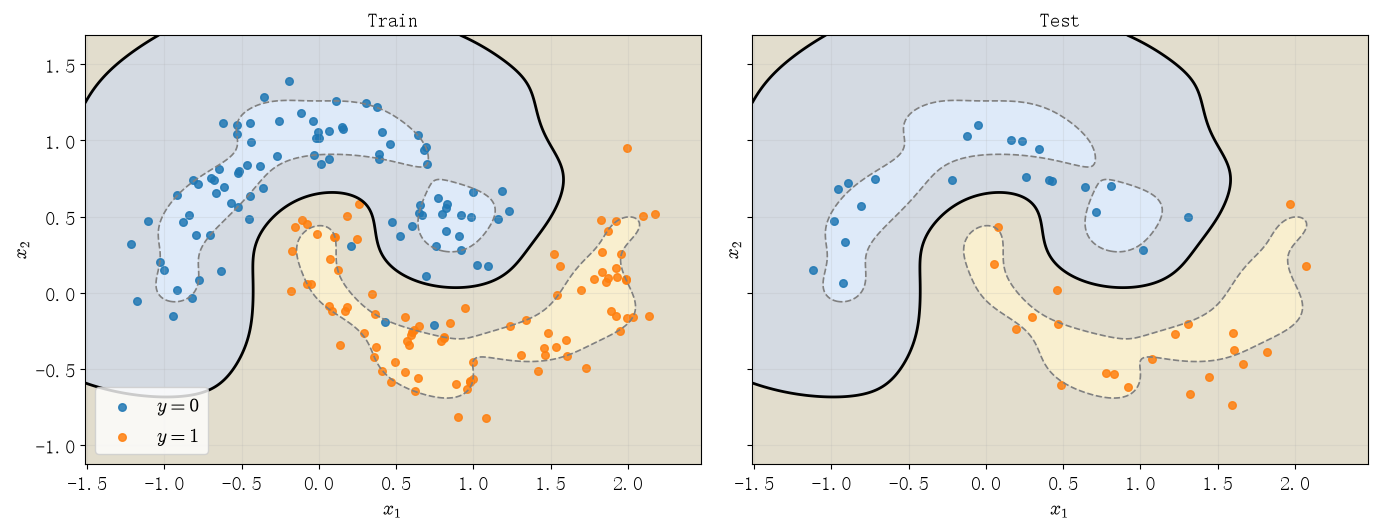

In [20]:
grid_size = 350
padding = 0.3

x1 = np.linspace(X_moon[:, 0].min() - padding, X_moon[:, 0].max() + padding, grid_size)
x2 = np.linspace(X_moon[:, 1].min() - padding, X_moon[:, 1].max() + padding, grid_size)

xx1, xx2 = np.meshgrid(x1, x2)
X_grid = np.column_stack((xx1.ravel(), xx2.ravel()))

F = best_model.decision_function(X_grid).reshape(xx1.shape)
Z = best_model.predict(X_grid).reshape(xx1.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)

for ax, X_part, y_part, name in zip(
    axes,
    [X_m_train, X_m_test],
    [y_m_train, y_m_test],
    ["Train", "Test"]
):
    ax.contourf(
        xx1, xx2, Z, levels=[-0.5, 0.5, 1.5],
        colors=["#C8DCF5", "#F6E5B0"], alpha=0.6
    )

    ax.contourf(
        xx1, xx2, F, levels=[-1, 1],
        colors=["#CCCCCC"], alpha=0.5
    )

    ax.contour(
        xx1, xx2, F, levels=[-1, 0, 1],
        colors=["gray", "black", "gray"],
        linestyles=["--", "-", "--"], linewidths=[1.2, 2, 1.2]
    )

    for label, color in [(0, "C0"), (1, "C1")]:
        ax.scatter(
            X_part[y_part == label, 0], X_part[y_part == label, 1],
            c=color, s=30, alpha=0.85, label=fr"$y={label}$"
        )

    ax.set(xlabel="$x_1$", ylabel="$x_2$", title=name)
    ax.grid(True, alpha=0.2)
axes[0].legend(loc="lower left")
display_inline(fig)

#### 混淆矩阵

为了进一步分析模型的分类结果, 我们分别计算 Train 和 Test 上的混淆矩阵.

对于二分类问题, 混淆矩阵为

$$
CM=
\begin{pmatrix}
TN&FP\\
FN&TP
\end{pmatrix}
$$

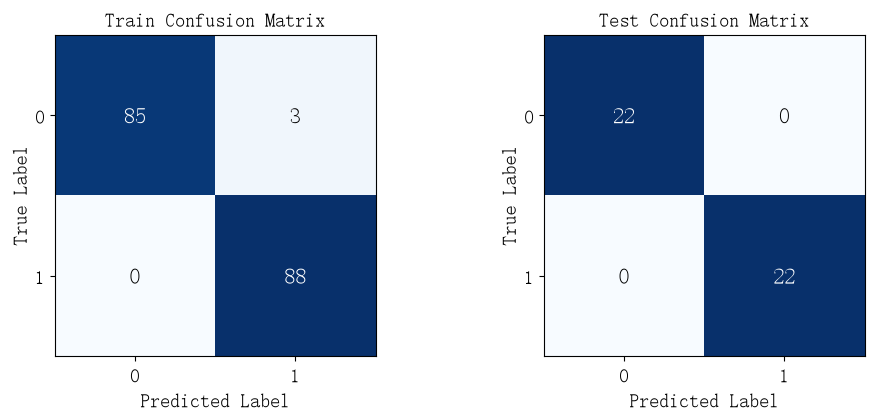

In [21]:
y_pred_train = best_model.predict(X_m_train)
y_pred_test = best_model.predict(X_m_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, y, y_pred, name in zip(
    axes,
    [y_m_train, y_m_test],
    [y_pred_train, y_pred_test],
    ["Train", "Test"]
):
    cm = confusion_matrix(y, y_pred)
    im = ax.imshow(cm, cmap="Blues")

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center", va="center", fontsize=16,
                color="white" if cm[i, j] > cm.max() / 2 else "black"
            )

    ax.set(
        xticks=[0, 1], yticks=[0, 1],
        xlabel="Predicted Label", ylabel="True Label",
        title=f"{name} Confusion Matrix"
    )

display_inline(fig)

从混淆矩阵可以看见, 模型在 Train 上正确分类了 $173$ 个样本, 其中有 $3$ 个类别为 $0$ 的样本被错误分类为 $1$, 其余样本均分类正确.

对于 Test, 模型正确分类了全部 $44$ 个样本, 没有出现分类错误.

这说明模型在当前数据划分下具有较好的分类效果.

#### Acc、Precision、Recall、F1

我们进一步使用 Accuracy、Precision、Recall 和 F1 Score 对分类模型进行定量评估.

In [22]:
def classification_metrics(y, y_pred):
    acc = accuracy_score(y, y_pred)
    prec = precision_score(y, y_pred)
    rec = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    return acc, prec, rec, f1

metrics = pd.DataFrame(
    [
        classification_metrics(y_m_train, y_pred_train),
        classification_metrics(y_m_test, y_pred_test)
    ],
    index=["Train", "Test"],
    columns=["Accuracy", "Precision", "Recall", "F1"]
)

print(f"Best C = {best_C:.6f}")
print(f"Best Gamma = {best_gamma_svm:.6f}")
print(f"Best CV Accuracy = {grid_search.best_score_:.6f}")

display(metrics.round(6))

Best C = 0.278256
Best Gamma = 3.593814
Best CV Accuracy = 0.977143


,Accuracy,Precision,Recall,F1
Train,0.982955,0.967033,1.0,0.98324
Test,1.000000,1.000000,1.0,1.00000


最终模型在 Train 上的 Accuracy 为 $0.982955$, F1 为 $0.983240$, 在 Test 上的 Accuracy 和 F1 均为 $1$, 表明模型能够较好地描述 Moon 数据集的结构.

从混淆矩阵可以看见, Train 上仅有 $3$ 个样本被错误分类, Test 中的全部 $44$ 个样本均被正确分类. 同时, CV Accuracy 与 Train Accuracy 比较接近, 没有观察到明显的泛化能力下降.

综上, 通过 RBF Kernel 和交叉验证优化, SVM 在本次 Moon 分类任务中取得了较好的分类效果.

### Pipeline 与防止数据泄漏

在机器学习任务中, 数据泄漏是指模型在训练过程中使用了本不应该获得的信息, 从而可能导致模型的评估结果过于乐观.

本次使用 `StandardScaler` 对输入特征进行标准化, 其计算公式为

$$
x'_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}
$$

其中 $\mu_j$ 和 $\sigma_j$ 分别为第 $j$ 个特征的均值和标准差.

这里需要注意两个问题.

**1. Train 和 Test 之间的数据泄漏**

如果在划分数据集之前就对全部数据进行标准化, 那么计算均值和标准差时就使用了 Test 的信息.

正确的处理方式是只使用 Train 计算标准化参数, 并将相同的标准化变换应用于 Test.

**2. 交叉验证过程中的数据泄漏**

即使已经划分 Train 和 Test, 如果提前使用完整 Train 计算均值和标准差, 再进行交叉验证, 同样会发生数据泄漏.

因为在每一轮交叉验证中, 当前验证的数据也参与了标准化参数的计算. 每一轮都只使用当前训练折计算标准化参数, 而不能使用对应验证的信息.

通过使用 `Pipeline` 将 `StandardScaler` 和 `SVC` 组合, 并将整个 Pipeline 传入 `GridSearchCV`.

在每一轮交叉验证中, `GridSearchCV` 都会重新将当前的训练数据传入 Pipeline, 因此 `StandardScaler` 只会使用当前训练的数据计算均值和标准差, 随后将相同的变换应用于验证.

当超参数优化完成后, `GridSearchCV` 会使用完整 Train 重新拟合最优 Pipeline. 最终对 Test 进行预测时, Pipeline 直接使用 Train 计算得到的标准化参数, 而不会重新拟合 `StandardScaler`. 从而避免了数据泄漏.

除此之外，在超参优化时，如果使用了 Test 进行评估，在使用 Test 挑选最优的模型时，挑选的过程本身也泄漏了 Test 信息，造成评估结果过于乐观.

**3. 超参数调优过程中的数据泄漏**

如果在超参数调优过程中使用 Test 计算模型性能, 并根据 Test 的结果选择最优参数, 那么 Test 实际上也参与了模型的选择, 从而发生数据泄漏, 导致最终评估结果可能过于乐观.

本次使用 `GridSearchCV` 进行超参数优化时, 只将 Train 传入，Test 不传入，保证优化处理等都是在 Train 上进行的.


## 结论

本次实验通过高斯核与 Normal Equation 实现非线性函数拟合, 并使用 `sklearn` 的 `Pipeline` 和 `GridSearchCV` 完成 Moon 数据集的 SVM 分类. 通过对超参数进行扫描, 分析了高斯核参数、正则化强度以及模型泛化能力之间的关系, 并进一步讨论了 Pipeline 在数据预处理和超参数优化中防止数据泄漏的作用. 得到以下结论：

- 高斯核能够有效描述非线性关系. 核岭回归通过核矩阵隐式完成高维特征映射, 并利用 Normal Equation 直接求解模型参数, 无需显式构造高维特征.

- $\gamma$ 对核回归的拟合能力具有明显影响. 随着 $\gamma$ 增大, Val MSE 呈现先下降后上升的趋势. 当 $\gamma$ 较小时, 高斯核作用范围较大, 模型难以描述原函数的快速振荡, 出现欠拟合. 当 $\gamma$ 较大时, 模型对局部变化更加敏感, 虽然训练误差可以进一步下降, 但容易拟合随机噪声, 导致验证误差上升.

- $\lambda$ 通过正则化控制模型复杂度, 并与 $\gamma$ 存在耦合. 当 $\lambda$ 较小时, 模型受到的约束较弱, 容易受到随机噪声影响. 随着 $\lambda$ 增大, 过拟合可以得到一定程度的抑制, 但过大的 $\lambda$ 又会导致欠拟合.

- 在本次实验中, 固定最优 $\gamma$ 后, 不同 $\lambda$ 对拟合曲线形状的影响并不十分明显, 相比之下 $\gamma$ 的影响更加显著. 二维超参数扫描还表明, 最优 $\lambda$ 会随 $\gamma$ 改变，因此二者需要同时扫描.

- Pipeline 能够规范数据预处理与超参数优化过程, 避免常见的数据泄漏，同时将训练时数据的处理进行抽象，从而使得参数扫描和训练可以通用. 比如这里将 Pipeline 和 Train 传入 `GridSearchCV`, 自动了保证每轮交叉验证中的预处理过程正确执行.

- 任务一的核岭回归在 $\gamma=5.6234,\lambda=0.1$ 时, Test MSE 为 $0.013194$, $R^2$ 为 $0.975873$, 预测误差已经接近随机噪声造成的误差水平

- 任务二的 RBF SVM 在 $C=0.2783,\gamma=3.5938$ 时, 平均 CV Accuracy 为 $0.977143$, Test 上的 Accuracy、Precision、Recall 和 F1 均达到 $1$.


总体而言, 本次实验进一步展示了核方法如何通过隐式特征映射处理非线性问题, 以及模型复杂度、正则化和泛化能力之间的关系. 同时, 从手动实现核回归到使用 `sklearn` 的 Pipeline 工作流, 也体现了机器学习实验中数值计算效率、超参数优化和规范化数据处理的重要性.

## 参考资料及 AI 使用说明

- 背景补充部分个人写出大体大纲，使用 GPT 6 Astra 生成并进行人工核验和修改.
- 代码编写使用 Deepseek V4 Flash FIM 模式进行补全和生成（尤其是绘图相关函数，基本是直接生成），经过人工核验和运行验证.
- 扫参函数由 GPT 6 生成，经过人工核验和运行验证.
- 文本和公式编写使用 Deepseek V4 Flash FIM 模式进行生成和补全，经过人工核验和修改.
- 部分结果描述使用 GPT 6 给出，经过人工核验和修改.
- 问题中的相关讨论和思考个人提供原始想法，并与 GPT 6 交流讨论整理而成.

## 致谢

暂无

## 附一：问题与思考

### 高斯核 SVM 和热扩散问题的相关讨论和思考

考虑 $d$ 维输入数据 $\boldsymbol x\in\mathbb R^d$. 高斯核函数定义为

$$
K_\gamma(\boldsymbol x,\boldsymbol x_i)=\exp\left(-\gamma\|\boldsymbol x-\boldsymbol x_i\|^2\right)
$$

其中 $\gamma>0$ 为核函数的参数，控制数据点的“影响范围”. 对于二分类数据，高斯核 SVM 的决策函数为

$$
f(\boldsymbol x)=\sum_{i=1}^N\alpha_i y_i \exp\left(-\gamma\|\boldsymbol x-\boldsymbol x_i\|^2\right)+b
$$

其中 $\alpha_i$ 是优化系数，$b$ 是截距。只有 $\alpha_i>0$ 的样本直接出现在求和中，这些样本称为支持向量. 分类规则为

$$
\hat y(\boldsymbol x)=\operatorname{sign}(f(\boldsymbol x))
$$

另一方面，我们知道，热传导的 Green 函数为（也就是 $t'$ 时刻的 $\delta(\boldsymbol x-\boldsymbol x')$ 的热源在 $t$ 时刻的分布）为：

$$
G( \boldsymbol x, t ; \boldsymbol x',t') =\frac{1}{(4\pi D(t-t'))^{d/2}}\exp\left(-\frac{\|\boldsymbol x-\boldsymbol x'\|^2}{4D(t-t')}\right)
$$

其中 $D$ 是热扩散系数. 取初始时刻为 $t'=0$，有：

$$
G_D(\boldsymbol x,t;\boldsymbol x')=\frac{1}{(4\pi Dt)^{d/2}} \exp\left(-\frac{\|\boldsymbol x - \boldsymbol x' \|^2}{4Dt}\right)
$$

假设空间中初始有多个 $\delta$ 热源，位置为 $\boldsymbol x_i$，强度为 $Q_i$，经过时间 $t$ 后的解为：

$$
u(\boldsymbol x,t)=\sum_{i=1}^N\frac{Q_i}{(4\pi Dt)^{d/2}}
\exp\left(-\frac{\|\boldsymbol x-\boldsymbol x_i\|^2}{4Dt}\right) + b
$$

其中额外的 $b$ 是均匀的背景温度场.

我们与高斯核 SVM 的决策函数比较：

$$
f(\boldsymbol x)=\sum_{i=1}^N\alpha_i y_i \exp\left(-\gamma\|\boldsymbol x-\boldsymbol x_i\|^2\right)+b
$$

不难注意到，在忽略相差的归一化系数下（我们总可以将归一化系数融进权重或点源强度中），因此，我们可以将 SVM 的决策函数给定时间的多个点源叠加的温度场，满足如下对应关系：

$$
\gamma \leftrightarrow \frac{1}{4Dt},\quad Q_i = \alpha_i y_i
$$

此时很容易通过物理直观看出：

$$
\gamma\uparrow\ \Longleftrightarrow\ t\downarrow, \quad
\gamma\downarrow\ \Longleftrightarrow\ t\uparrow
$$

- 大 $\gamma$：对应较短扩散时间，点源影响更局部
- 小 $\gamma$：对应较长扩散时间，点源影响范围更广

通过如上的数学形式上的对应，我们知道，任意一个训练完成的高斯核 SVM，都可以对应到一个带符号点源，使其在指定时刻的场分布与 SVM 决策函数完全一致. 

其中，原始标签 +1 对应正温度热源，原始标签 -1 对应负温度热源，其中负温度热源可以认为我们温度零点没有选取 0K，从而解决物理中一般没有负温度的问题.

最重要的三个等值面为

$$
\begin{aligned}
f(\boldsymbol x)&=0 &&\text{分类边界}\\
f(\boldsymbol x)&=+1 &&\text{正间隔边界}\\
f(\boldsymbol x)&=-1 &&\text{负间隔边界}
\end{aligned}
$$

根据前面构造的 $u(\boldsymbol x,t_0)=f(\boldsymbol x)$，这些等值面恰好对应扩散场在 $t_0$ 的 $u=0,\pm1$ 等温面.

### 高斯核 SVM 和 Hilbert 空间的相关讨论和思考

量子力学中，我们很熟悉 Hilbert 空间. Hilbert 空间是定义有内积的完备的线性空间，一般而言，我们取内积为 $L^2$ 范数，取平方可积函数作为线性空间，这也是量子力学中一般所说的 Hilbert 空间，其是无穷维的.

好，那么我们回顾前面的分析，对于某一个数据点，给定 $\gamma$ 的情况下，其对应某一段时间后的温度场. 也就是对应一个函数，记这种对应关系为 $\Phi_{\gamma,\boldsymbol x}(\boldsymbol z)$，我们构造（其实是从高斯核反推的，但这里认为是直接构造即可，后面给出和高斯核关系）：

定义

$$
\Phi_{\gamma, \boldsymbol x} (\boldsymbol z) =\left(\frac{4\gamma}{\pi}\right)^{d/4}
\exp\left(-2\gamma\|\boldsymbol z-\boldsymbol x\|^2\right)
$$

其是如下的映射：

$$
\Phi:\mathbb R^d \to L^2(\mathbb R^d)
$$

注意两个变量的区别：$\boldsymbol x$ 是输入数据点；$\boldsymbol z$ 是映射后函数的自变量. 输入一个向量 $\boldsymbol x$，就得到一个以该点为中心的完整高斯函数. 

不难得到：

$$
K_\gamma(\boldsymbol x,\boldsymbol y) =\langle\Phi_{\gamma,\boldsymbol x},\Phi_{\gamma,\boldsymbol y}\rangle
$$

换句话说，其高斯核是数据点 $\boldsymbol x$ 和 $\boldsymbol y$ 经过映射 $\Phi$ 后在 Hilbert 空间中的内积. 换句话说，其代表数据点经过特征映射后的特征的相似性.

因此，核 SVM 将数据映射到无穷维 Hilbert 空间中进行线性分类并让间隔最大化.

由于

$$
\|\Phi_{\gamma, \boldsymbol x}=K_\gamma(\boldsymbol x,\boldsymbol x)=1
$$

因此，所有数据点落在高维空间的一个球面上，任意两个数据点映射后的距离满足

$$
\begin{aligned}
\|\Phi_{\gamma,\boldsymbol x}-\Phi_{\gamma,\boldsymbol y}\|&=\|\Phi_{\gamma,\boldsymbol x}\|^2+\|\Phi_{\gamma,\boldsymbol y}\|^2-2\langle\Phi_{\gamma,\boldsymbol x},\Phi_{\gamma,\boldsymbol y}\rangle\\
&=2-2e^{-\gamma\|\boldsymbol x-\boldsymbol y\|^2}
\end{aligned}
$$

因此，高维特征空间中两个点的距离定义为：

$$
d_{\mathcal H}(\boldsymbol x,\boldsymbol y)=
\sqrt{2\left(1-e^{-\gamma\|\boldsymbol x-\boldsymbol y\|^2}\right)}
$$

固定两个不同输入点：

$$
\gamma\to0^+\quad\Longrightarrow\quad d_{\mathcal H}\to0
$$

$$
\gamma\to+\infty\quad\Longrightarrow\quad d_{\mathcal H}\to\sqrt2
$$

因此 $\gamma$ 它还决定数据在特征空间中如何分布。小 $\gamma$ 使数据点映射后接近；大 $\gamma$ 使不同数据点的特征向量逐渐接近正交. 

当 $\gamma\to\infty$ 时，其每一个数据点指向一个正交的方向，其是一种极端的 Onehot 编码（字典态），这相当于丢失了原始数据空间中一个十分重要的性质：两个位置相近的输入，其分类结果通常也应该具有某种关联. 从而出现严重的过拟合.


### 总结

- 在忽略相差的归一化系数下（我们总可以将归一化系数融进权重或点源强度中），我们可以将 SVM 的决策函数当成给定时间的多个点源叠加的温度场，满足如下对应关系：

$$
\gamma \leftrightarrow \frac{1}{4Dt},\quad Q_i = \alpha_i y_i
$$

- 大 $\gamma$：对应较短扩散时间，点源影响更局部，小 $\gamma$：对应较长扩散时间，点源影响范围更广

- 分类边界对应 $T=0$ 等温面，间隔边界对应 $T=\pm1$ 等温面

- 我们可以特定构造特征映射，将数据点映射到无穷维 Hilbert 空间，一个数据点映射成一个函数，高斯核即这些函数的内积. 核 SVM 对应在这个高维空间中的线性分类并找到最大间隔.

- 高斯核对应的特征映射将所有数据映射到一个高维球面上，当 $\gamma\to0$，特征空间中数据点趋近于同一点；当 $\gamma\to+\infty$，不同点的特征趋近正交，模型趋于 Onehot 编码，容易过拟合.

这种对应关系是有趣的，也许可以用一种新的方法和视角分析 SVM 的性质，给出一些有趣的对应和推论

## 附二：学习心得

暂无